<div dir="rtl">

# نوت‌بوک ۱: ممیزی ساختار داده

**فاز ۱، تسک ۴**

این نوت‌بوک به یک سؤال جواب می‌دهد: **داده‌ی ما دقیقاً چه شکلی است؟**

- هر فایل چند ردیف و چند ستون دارد و هر ستون از چه نوعی است؟
- شناسه‌ها (محصول، نسخه‌ی محصول، کاربر) چطور کار می‌کنند؟
- دو فایل نقدها و اطلاعات محصول چطور به هم وصل‌اند؟
- متغیر زمان چه بازه‌ای را پوشش می‌دهد؟
- زیرمجموعه‌ی کنترل از راه دور از چه زیرشاخه‌هایی ساخته شده است؟

ورودی: خروجی `src/build_subset.py` در `data/processed/`.
بررسی کیفیت (مقادیر گمشده، تکراری، پرت) موضوع نوت‌بوک ۲ است.

</div>

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load(open(ROOT / "configs" / "config.yaml", encoding="utf-8"))
PROC = ROOT / cfg["data"]["processed_dir"]
FIG = ROOT / "figures"

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

reviews = pd.read_parquet(PROC / "reviews_rc.parquet")
meta = pd.read_parquet(PROC / "meta_rc.parquet")
audit = json.load(open(ROOT / "reports" / "phase1" / "raw_schema_audit.json"))

print(f"reviews: {reviews.shape[0]:,} rows x {reviews.shape[1]} columns")
print(f"meta:    {meta.shape[0]:,} rows x {meta.shape[1]} columns")

reviews: 862,444 rows x 11 columns
meta:    71,046 rows x 17 columns


<div dir="rtl">

## ۱. ستون‌ها و نوع داده

برای هر ستون: نوع ذخیره‌شده، درصد ردیف‌هایی که مقدار دارند، و یک نمونه مقدار.
ستون‌هایی که با «JSON» مشخص شده‌اند در فایل خام لیست یا دیکشنری بوده‌اند و به‌صورت متن ذخیره شده‌اند تا ساختار جدول یکدست بماند.

</div>

In [2]:
def column_table(df):
    rows = []
    for c in df.columns:
        s = df[c]
        non_null = s.notna().mean() * 100
        example = s.dropna().iloc[0] if s.notna().any() else None
        if isinstance(example, str) and len(example) > 60:
            example = example[:60] + "..."
        rows.append({"column": c, "dtype": str(s.dtype),
                     "non_null_%": round(non_null, 1), "example": example})
    return pd.DataFrame(rows)

column_table(reviews)

,column,dtype,non_null_%,example
0,rating,float64,100.0,5.0
1,title,str,100.0,super fun but be VERY CAREFUL>
2,text,str,100.0,this is not a toy. but it is pretty awesome. I wouldn't le...
3,images,str,100.0,[]
4,n_images,int32,100.0,0
5,asin,str,100.0,B013U0F6EQ
6,parent_asin,str,100.0,B01C6FRASG
7,user_id,str,100.0,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ
8,timestamp,int64,100.0,1456772324000
9,helpful_vote,int64,100.0,1


In [3]:
column_table(meta)

,column,dtype,non_null_%,example
0,parent_asin,str,100.0,B019XEEX1A
1,main_category,str,97.9,Toys & Games
2,title,str,100.0,"Traxxas Stampede 4X4: 1/10 Scale 4wd Monster Truck, Red"
3,store,str,99.8,Traxxas
4,average_rating,float64,100.0,4.5
5,rating_number,int64,100.0,48
6,price,float64,51.7,69.99
7,price_raw,str,51.7,69.99
8,categories,str,100.0,"[""Toys & Games"", ""Remote & App Controlled Vehicles & Parts"",..."
9,features,str,100.0,"[""Waterproof electronics for all-weather driving excitement ..."


<div dir="rtl">

## ۲. ناسازگاری نوع در فایل خام

اسکریپت ساخت زیرمجموعه برای **هر فیلد در هر خط** از ۱۷ میلیون خط خام شمرده است که چه نوع مقداری داشته.
فیلدهایی که بیش از یک نوع داشته‌اند در جدول زیر آمده‌اند.

- `missing` یعنی فیلد در خط بوده ولی مقدارش خالی (null) بوده است.
- `absent` یعنی فیلد اصلاً در آن خط وجود نداشته است.

این شمارش روی **کل دسته‌ی اسباب‌بازی** است، نه فقط زیرمجموعه.

</div>

In [4]:
rows = []
for part in ("reviews", "meta"):
    for field, types in audit["field_types"][part].items():
        total = sum(types.values())
        for t, n in types.items():
            rows.append({"file": part, "field": field, "type": t,
                         "count": n, "share_%": round(100 * n / total, 2)})
types_df = pd.DataFrame(rows)

n_types = types_df.groupby(["file", "field"])["type"].nunique()
mixed = n_types[n_types > 1].index
types_df.set_index(["file", "field"]).loc[mixed].reset_index()

,file,field,type,count,share_%
0,meta,author,dict,17,0.00
1,meta,author,missing,8,0.00
2,meta,author,absent,890849,100.00
3,meta,main_category,str,869017,97.55
4,meta,main_category,missing,21857,2.45
5,meta,price,missing,462209,51.88
6,meta,price,float,428665,48.12
7,meta,store,str,885517,99.40
8,meta,store,missing,5357,0.60
9,meta,subtitle,str,21,0.00


<div dir="rtl">

## ۳. شناسه‌ها

سه شناسه داریم:

| شناسه | معنی |
|---|---|
| `parent_asin` | محصول (همه‌ی رنگ‌ها و اندازه‌ها با هم) و **واحد محصول ما** |
| `asin` | یک نسخه‌ی مشخص (مثلاً رنگ قرمز) |
| `user_id` | نقدنویس؛ فقط شناسه‌ی تحلیلی است و برای شناسایی افراد استفاده نمی‌شود |

</div>

In [5]:
ids = pd.Series({
    "products in meta (rows)": len(meta),
    "unique parent_asin in meta": meta["parent_asin"].nunique(),
    "unique parent_asin in reviews": reviews["parent_asin"].nunique(),
    "unique asin (variants) in reviews": reviews["asin"].nunique(),
    "unique user_id in reviews": reviews["user_id"].nunique(),
})
ids.map("{:,}".format)

products in meta (rows)               71,046
unique parent_asin in meta            71,046
unique parent_asin in reviews         71,043
unique asin (variants) in reviews     78,575
unique user_id in reviews            567,231
dtype: str

<div dir="rtl">

### چند نسخه برای هر محصول؟ چند نقد برای هر کاربر؟

</div>

In [6]:
variants = reviews.groupby("parent_asin")["asin"].nunique()
per_user = reviews.groupby("user_id").size()

summary = pd.DataFrame({
    "variants per product": variants.describe(percentiles=[.5, .9, .99]),
    "reviews per user": per_user.describe(percentiles=[.5, .9, .99]),
}).round(2)
summary

,variants per product,reviews per user
count,71043.00,567231.00
mean,1.11,1.52
std,0.62,2.21
min,1.00,1.00
50%,1.00,1.00
90%,1.00,2.00
99%,4.00,9.00
max,40.00,200.00


<div dir="rtl">

## ۴. ارتباط دو فایل

رابطه‌ی دو فایل **چند به یک** است: هر نقد دقیقاً به یک محصول تعلق دارد و هر محصول می‌تواند صفر یا چند نقد داشته باشد. کلید اتصال `parent_asin` است.

</div>

In [7]:
meta_ids = set(meta["parent_asin"])
review_ids = set(reviews["parent_asin"])

link = pd.Series({
    "reviews whose product is in meta": reviews["parent_asin"].isin(meta_ids).sum(),
    "reviews whose product is NOT in meta": (~reviews["parent_asin"].isin(meta_ids)).sum(),
    "products with at least one review": len(meta_ids & review_ids),
    "products with no review": len(meta_ids - review_ids),
})
link.map("{:,}".format)

reviews whose product is in meta        862,444
reviews whose product is NOT in meta          0
products with at least one review        71,043
products with no review                       3
dtype: str

In [8]:
per_product = reviews.groupby("parent_asin").size()
per_product.describe(percentiles=[.25, .5, .75, .9, .99]).round(1)

count    71043.0
mean        12.1
std         84.0
min          1.0
25%          1.0
50%          2.0
75%          6.0
90%         19.0
99%        152.0
max       5769.0
dtype: float64

<div dir="rtl">

## ۵. متغیر زمان

`timestamp` زمان ثبت نقد به میلی‌ثانیه از ۱ ژانویه‌ی ۱۹۷۰ (Unix time) است. آن را به تاریخ تبدیل می‌کنیم.
بررسی کامل الگوهای زمانی در نوت‌بوک تحلیل اکتشافی می‌آید؛ اینجا فقط بازه و پوشش را می‌بینیم.

</div>

In [9]:
reviews["date"] = pd.to_datetime(reviews["timestamp"], unit="ms", utc=True)
print("first review:", reviews["date"].min())
print("last review: ", reviews["date"].max())
print("missing timestamps:", reviews["timestamp"].isna().sum())

reviews["date"].dt.year.value_counts().sort_index().to_frame("reviews")

first review: 2001-07-03 03:28:08+00:00
last review:  2023-09-11 20:08:41.115000+00:00
missing timestamps: 0


,reviews
date,
2001,1
2002,2
2003,6
2004,18
2005,42
2006,37
2007,120
2008,158
2009,299


<div dir="rtl">

## ۶. زیرشاخه‌های زیرمجموعه

مسیر دسته‌بندی آمازون (`categories`) را باز می‌کنیم و سطح سوم آن را می‌شماریم.
این نشان می‌دهد زیرمجموعه چقدر «وسیله‌ی کامل» (ماشین، پهپاد، هلی‌کوپتر) و چقدر «قطعه و لوازم جانبی» است.
تصمیم تسک ۴: قطعات نگه داشته می‌شوند و در فاز ۴ به‌عنوان زیرگروه مقایسه می‌شوند.

</div>

In [10]:
def level(cats_json, k):
    cats = json.loads(cats_json) if cats_json else []
    return cats[k] if len(cats) > k else "(none)"

meta["cat_level2"] = meta["categories"].map(lambda c: level(c, 1))
meta["cat_level3"] = meta["categories"].map(lambda c: level(c, 2))

n_reviews = reviews.groupby("parent_asin").size()
meta["n_reviews"] = meta["parent_asin"].map(n_reviews).fillna(0).astype(int)

sub = (meta.groupby("cat_level3")
           .agg(products=("parent_asin", "size"), reviews=("n_reviews", "sum"))
           .sort_values("reviews", ascending=False))
sub["reviews_%"] = (100 * sub["reviews"] / sub["reviews"].sum()).round(1)
sub

,products,reviews,reviews_%
cat_level3,,,
Remote & App Controlled Vehicles,11647,269609,31.3
Remote & App Controlled Vehicle Parts,35506,261490,30.3
Quadcopters & Multirotors,7146,218421,25.3
Power Plant & Driveline Systems,6632,31546,3.7
Robots,657,23912,2.8
Vehicle Bodies & Scale Accessories,4105,21190,2.5
Electric Motors & Parts,2158,11733,1.4
(none),807,7747,0.9
Train Tracks,214,6083,0.7


<div dir="rtl">

نمونه‌ای از عنوان محصولات در سه زیرشاخه‌ی پرنقد:

</div>

In [11]:
for name in sub.index[:3]:
    print(f"--- {name} ---")
    titles = meta.loc[meta["cat_level3"] == name, "title"].dropna()
    for t in titles.sample(min(5, len(titles)), random_state=cfg["seed"]):
        print("  ", t[:110])

--- Remote & App Controlled Vehicles ---
   UUmart WLtoys F959 Sky-King RC Airplane Spare Parts 7.4V 300mAh Li-po Battery
   Traxxas Aton Front Canopy, Blue/White
   HDMI Cable, TecBillion High Speed CL3 Rated 2.0 HDMI Cable, Braided HDMI Cord-Supports Ethernet, 4K, 3D and Au
   TX-BATT Li-Po LP1-2500 107A10981A
   Battery Replacement for YUNEEC H480 Drone Remote Control Part NO YP-3A
--- Remote & App Controlled Vehicle Parts ---
   Axial Spur Gear 32P 64T Yeti, AXIC1065
   Mavic Pro Battery, Aotu Intelligent Flight Battery for DJI Mavic Pro & Platinum & Alpine White Drone, 11.4V 38
   AKK X1P 5.8Ghz 25mW/200mW/600mW Switchable FPV AV Transmitter with Pigtail for FPV Racing Drone
   Axial SCX10 II Upgrade Parts (AX90046, AX90047, AXI90075) Aluminum 25T Servo Horn - 1Pc Set Orange
   Fytoo Helicopter Accessory 4PCS Landing Gear for Hubsan H501S H501A H501M H501S W H501S pro H501C X4 FPV Bushl
--- Quadcopters & Multirotors ---
   YYFRIEND Drone Accessories Aluminum Alloy Motor Cover Dust

<div dir="rtl">

## ۷. نمودار جریان داده

از فایل‌های خام تا جدول‌هایی که در بقیه‌ی پروژه استفاده می‌شوند.

</div>

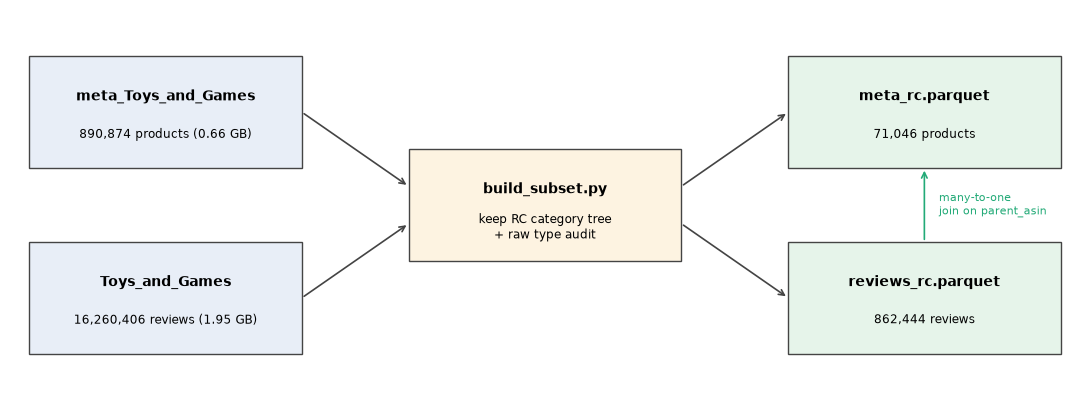

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.set_xlim(0, 11)
ax.set_ylim(0, 4.2)
ax.axis("off")

def box(x, y, w, h, title, sub, color):
    ax.add_patch(plt.Rectangle((x, y), w, h, facecolor=color, edgecolor="#444", lw=1))
    ax.text(x + w / 2, y + h * 0.64, title, ha="center", va="center", fontsize=10, weight="bold")
    ax.text(x + w / 2, y + h * 0.3, sub, ha="center", va="center", fontsize=8.5)

def arrow(x1, y1, x2, y2, label=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#444", lw=1.2))
    if label:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.15, label, ha="center", fontsize=8, color="#333")

raw, mid, out = "#e8eef7", "#fdf3e1", "#e6f4ea"
box(0.2, 2.5, 2.8, 1.2, "meta_Toys_and_Games", "890,874 products (0.66 GB)", raw)
box(0.2, 0.5, 2.8, 1.2, "Toys_and_Games", "16,260,406 reviews (1.95 GB)", raw)
box(4.1, 1.5, 2.8, 1.2, "build_subset.py", "keep RC category tree\n+ raw type audit", mid)
box(8.0, 2.5, 2.8, 1.2, "meta_rc.parquet", f"{len(meta):,} products", out)
box(8.0, 0.5, 2.8, 1.2, "reviews_rc.parquet", f"{len(reviews):,} reviews", out)

arrow(3.0, 3.1, 4.1, 2.3)
arrow(3.0, 1.1, 4.1, 1.9)
arrow(6.9, 2.3, 8.0, 3.1)
arrow(6.9, 1.9, 8.0, 1.1)
ax.annotate("", xy=(9.4, 1.7), xytext=(9.4, 2.5),
            arrowprops=dict(arrowstyle="<-", color="#2a7", lw=1.2))
ax.text(9.55, 2.1, "many-to-one\njoin on parent_asin", fontsize=8, color="#2a7", va="center")

plt.tight_layout()
FIG.mkdir(exist_ok=True)
plt.savefig(FIG / "fig01_data_flow.png", dpi=200, bbox_inches="tight")
plt.show()

<div dir="rtl">

## ۸. جمع‌بندی

**اندازه و سلامت**
- زیرمجموعه‌ی کنترل از راه دور: ۸۶۲٬۴۴۴ نقد (۱۱ ستون) و ۷۱٬۰۴۶ محصول (۱۷ ستون). هیچ خط خراب و هیچ محصول تکراری در فایل خام نبود.
- در فایل نقدها هیچ ناسازگاری نوعی دیده نشد و همه‌ی ستون‌ها ۱۰۰٪ پرند.

**فایل اطلاعات محصول**
- **قیمت** همیشه عددی است ولی برای ۴۸٪ محصولات زیرمجموعه خالی است (۵۲٪ در کل دسته). گمشدگی قیمت در تسک ۶ بررسی می‌شود.
- `bought_together` در هیچ محصولی مقدار ندارد و کنار گذاشته می‌شود. `author` و `subtitle` تقریباً در هیچ محصولی وجود ندارند.
- `average_rating` و `rating_number` برای همه پرند ولی در زمان جمع‌آوری حساب شده‌اند و **خطر نشت** دارند؛ به‌عنوان ویژگی مدل استفاده نمی‌شوند.

**شناسه‌ها و ارتباط دو فایل**
- رابطه‌ی دو فایل چند به یک است و همه‌ی نقدها به یک محصول در فایل اطلاعات وصل‌اند؛ فقط ۳ محصول هیچ نقدی ندارند.
- ۹۰٪ محصولات فقط یک نسخه (`asin`) دارند، ولی تا ۴۰ نسخه هم دیده می‌شود؛ تجمیع در سطح `parent_asin` برای این اقلیت ضروری است.
- بیش از نیمی از ۵۶۷ هزار نقدنویس فقط یک نقد نوشته‌اند؛ شناسه‌ی کاربر برای مدل‌سازی رفتار کاربر کافی نیست. کاربران پرنقد (تا ۲۰۰ نقد) در تسک ۵ بررسی می‌شوند.
- توزیع تعداد نقد هر محصول به‌شدت چوله است: میانه ۲ و میانگین ۱۲؛ ۹۰٪ محصولات در کل کمتر از ۲۰ نقد دارند. گزارش سه‌ماهه فقط برای محصولات پرنقد ممکن است.

**زمان**
- هیچ نقدی بدون زمان نیست. بازه از ۲۰۰۱ تا شهریور ۲۰۲۳ است ولی ۹۴٪ نقدها از ۲۰۱۵ به بعدند و اوج در ۲۰۲۰ و ۲۰۲۱ است.
- تعداد نقدها در ۲۰۲۳ ماه‌به‌ماه به‌شدت کم می‌شود (از ۱۶ هزار در ژانویه به ۱٫۹ هزار در اوت)؛ احتمالاً جمع‌آوری ماه‌های پایانی ناقص است. در تسک‌های ۹ و ۱۱ لحاظ می‌شود.

**زیرشاخه‌ها**
- سه زیرشاخه‌ی اصلی: وسایل نقلیه (۳۱٪ نقدها)، قطعات وسایل (۳۰٪) و پهپادها (۲۵٪).
- **برچسب زیرشاخه‌ها دقیق نیست:** در نمونه‌ی عنوان‌های شاخه‌ی «Vehicles» باتری، قطعه و حتی کابل HDMI دیده شد. برای مقایسه‌ی «وسیله‌ی کامل» و «قطعه» در فاز ۴ نمی‌توان فقط به این برچسب تکیه کرد.
- شاخه‌های «Robots» (۲٫۸٪) و «Train Tracks» (۰٫۷٪) هم در درخت آمازون زیر کنترل از راه دور قرار دارند و طبق تعریف ثبت‌شده در زیرمجموعه می‌مانند.

</div>